# 8. Protein model validation partition plots

This notebook reads the saved external validation predictions/metrics produced by `7. test_8020.ipynb` and creates final model-partition plots for each validation dataset.

For every validation dataset and every metric, proteins are assigned to the model/run that predicts them best:

- Pearson: highest `test_pearson_corr`
- Cosine: highest `test_cosine_similarity`
- MSE: lowest `test_mse`

Proteins that do not pass the quality threshold are placed into a red bad segment. Small good model segments are grouped into `Other good models` to keep the plots clean.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})


In [ ]:
OUTPUT_DIR = Path("../results_comparison_all_models")
METRICS_PROTEIN_CSV = OUTPUT_DIR / "eval_metrics_by_protein.csv"
METRICS_TISSUE_CSV = OUTPUT_DIR / "eval_metrics_by_tissue.csv"
PREDICTIONS_PARQUET = OUTPUT_DIR / "eval_predictions_long.parquet"
PREDICTIONS_CSV = OUTPUT_DIR / "eval_predictions_long.csv"

PEARSON_GOOD_THRESHOLD = 0.30
COSINE_GOOD_THRESHOLD = 0.30
MSE_GOOD_PERCENTILE = 25  # lower MSE is better; threshold is this percentile within each dataset
MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT = 200

if not METRICS_PROTEIN_CSV.exists():
    raise FileNotFoundError(f"Missing {METRICS_PROTEIN_CSV}. Run 7. test_8020.ipynb first.")

metrics_by_protein = pd.read_csv(METRICS_PROTEIN_CSV)
metrics_by_tissue = pd.read_csv(METRICS_TISSUE_CSV) if METRICS_TISSUE_CSV.exists() else pd.DataFrame()

print("Loaded protein metrics:", metrics_by_protein.shape)
print("Datasets:", sorted(metrics_by_protein["dataset"].dropna().unique()))
print("Run labels:", metrics_by_protein["run_label"].nunique())

display(metrics_by_protein.head())


Loaded protein metrics: (64881, 16)
Datasets: ['LabelFree', 'TMT', 'iTRAQ']
Run labels: 15


,dataset,protein,source_folder,model_family,normalization,grid_preset,select_k,run_label,h5_path,test_mse,test_pearson_corr,test_cosine_similarity,n_test_used,selected_feature_count,missing_feature_count,missing_feature_fraction
0,LabelFree,A2M,results_xgb,xgb,none,fast,2000,results_xgb | none | fast | k2000,..\results_xgb\A2M_xgb_8020_none_fast_k2000.h5,0.309270,0.216253,0.371375,360,2000,668,0.334
1,iTRAQ,A2M,results_xgb,xgb,none,fast,2000,results_xgb | none | fast | k2000,..\results_xgb\A2M_xgb_8020_none_fast_k2000.h5,0.688956,0.086966,0.010461,276,2000,668,0.334
2,TMT,A2M,results_xgb,xgb,none,fast,2000,results_xgb | none | fast | k2000,..\results_xgb\A2M_xgb_8020_none_fast_k2000.h5,5.736022,-0.368703,-0.043190,1924,2000,668,0.334
3,LabelFree,A2M,results_xgb,xgb,none,tiny,50,results_xgb | none | tiny | k50,..\results_xgb\A2M_xgb_8020_none_tiny_k50.h5,0.292603,0.067915,-0.132168,360,50,6,0.120
4,iTRAQ,A2M,results_xgb,xgb,none,tiny,50,results_xgb | none | tiny | k50,..\results_xgb\A2M_xgb_8020_none_tiny_k50.h5,0.518164,0.229213,0.056677,276,50,6,0.120


## 1. Concise overview

Model/run coverage by dataset, excluding k50 and k500


,dataset,run_label,proteins,median_pearson,median_cosine,median_mse
3,LabelFree,results_enet | ranking | fast | k2000,2155,0.113368,5.349470e-02,3.361032e+07
5,LabelFree,results_enet | zscore | fast | k2000,2155,0.103802,9.669994e-02,1.030591e+00
9,LabelFree,results_xgb | zscore | fast | k2000,2155,0.100798,5.271784e-02,1.156633e+00
1,LabelFree,res_xgb_zbig | zscore | current | k5000,2155,0.099510,5.179310e-02,1.155184e+00
0,LabelFree,res_enet_zbig | zscore | fast | k5000,2155,0.099160,9.242556e-02,1.057716e+00
7,LabelFree,results_xgb | qbin50 | fast | k2000,2155,0.087238,4.647627e-02,1.181905e+00
2,LabelFree,results_enet | none | fast | k2000,2155,0.087016,1.033444e-02,2.007185e+00
4,LabelFree,results_enet | unknown | fast | k2000,2155,0.085826,1.790948e-02,2.536887e+00
8,LabelFree,results_xgb | rank | fast | k2000,2155,0.080376,4.657988e-02,1.194250e+00
6,LabelFree,results_xgb | none | fast | k2000,2155,-0.007734,1.516288e-02,1.081109e+00


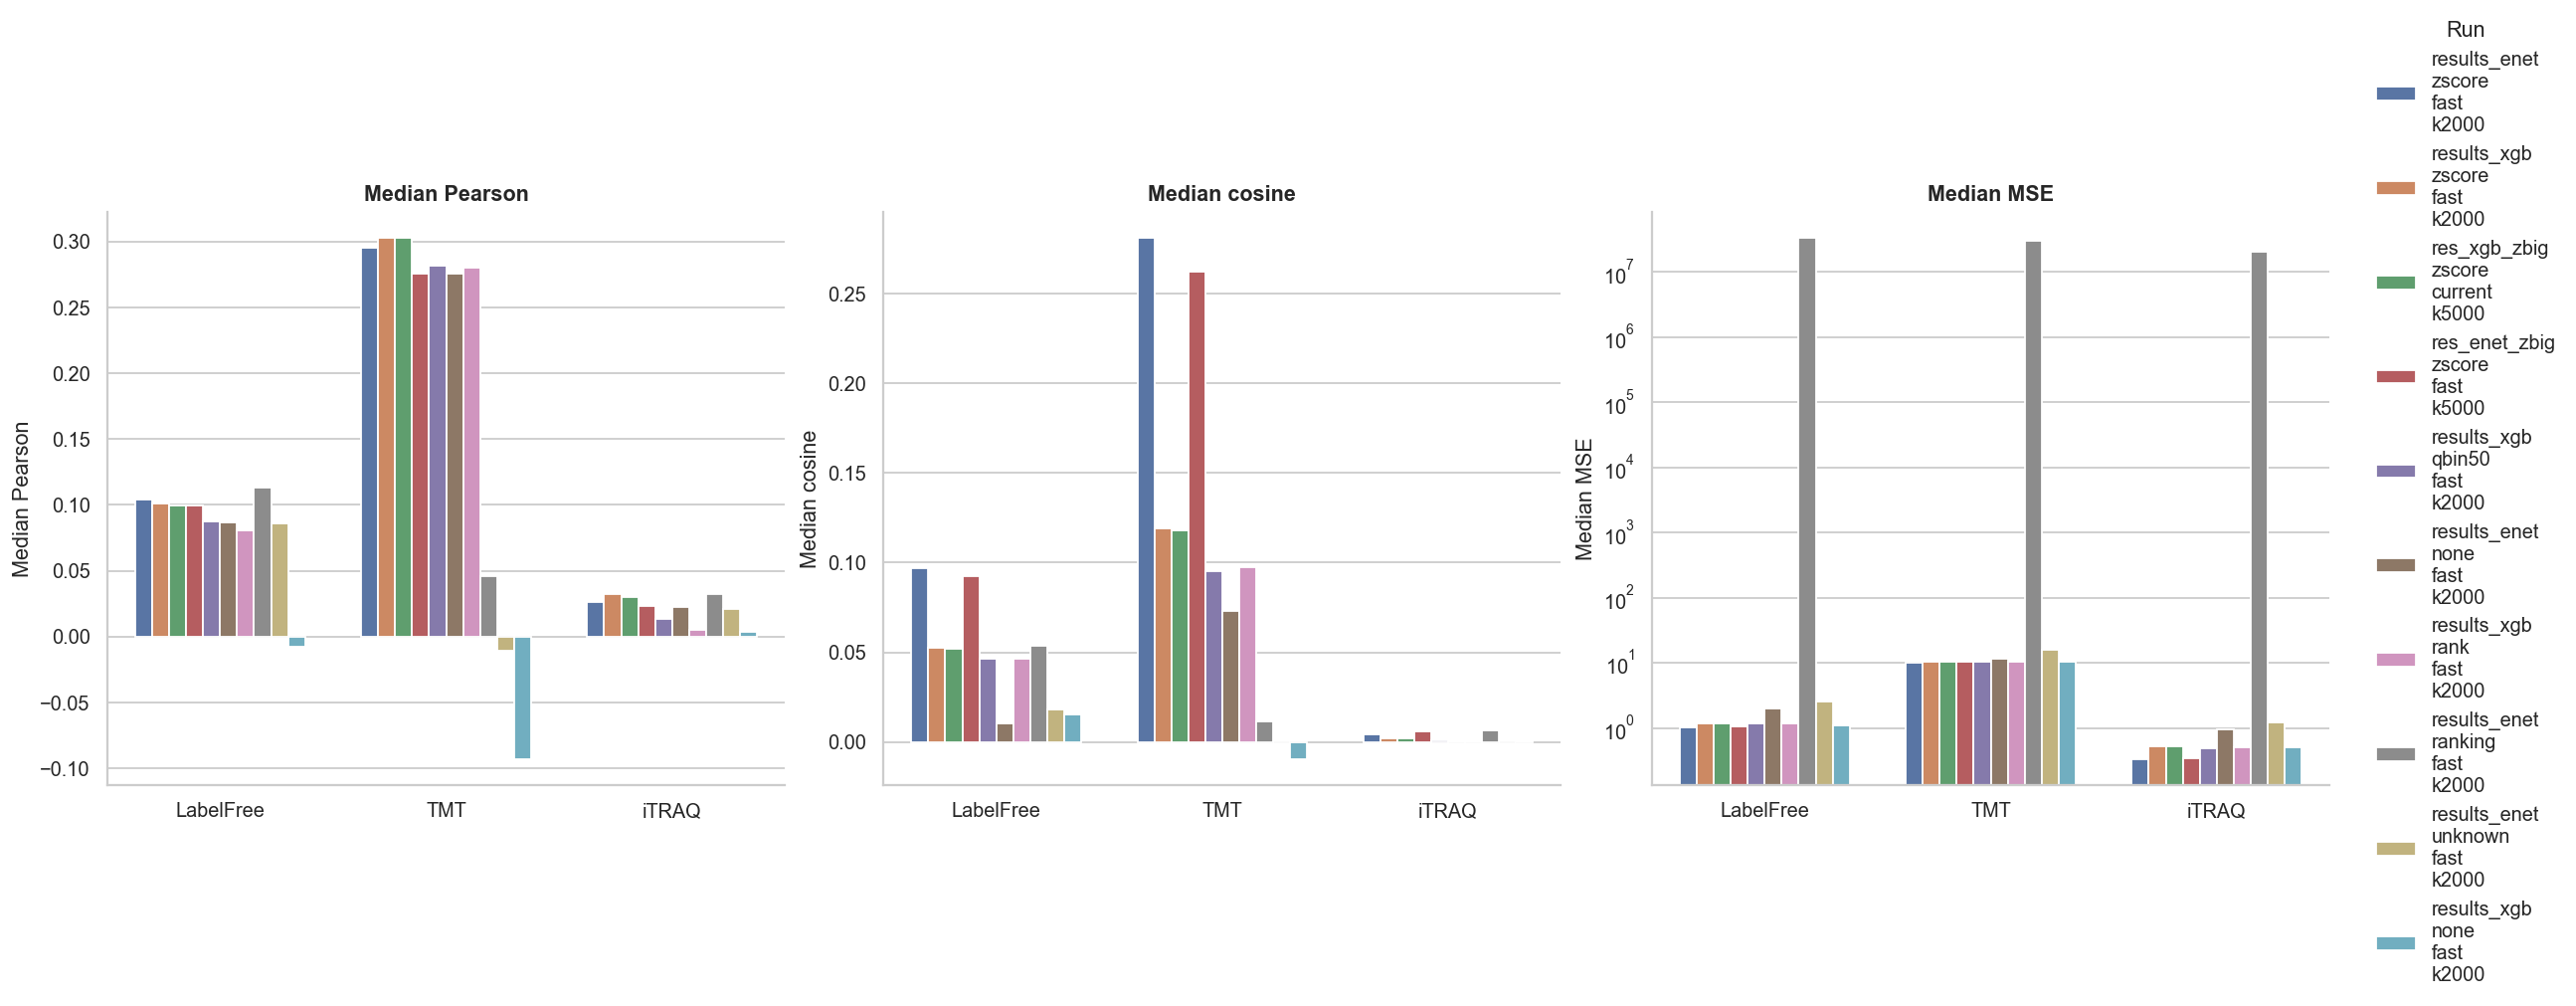

In [8]:
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Skip exact k50 and k500 models from the whole analysis
skip_k_pattern = r"\bk(?:50|500)\b"

metrics_filtered = metrics_by_protein[
    ~metrics_by_protein["run_label"]
    .astype(str)
    .str.contains(skip_k_pattern, case=False, regex=True, na=False)
].copy()

overview = (
    metrics_filtered.groupby(["dataset", "run_label"])
    .agg(
        proteins=("protein", "nunique"),
        median_pearson=("test_pearson_corr", "median"),
        median_cosine=("test_cosine_similarity", "median"),
        median_mse=("test_mse", "median"),
    )
    .reset_index()
)

print("Model/run coverage by dataset, excluding k50 and k500")
display(
    overview.sort_values(
        ["dataset", "median_pearson"],
        ascending=[True, False]
    )
)

# Cleaner run labels
overview["run_short"] = (
    overview["run_label"]
    .astype(str)
    .str.replace(" | ", "\n", regex=False)
)

# Consistent run order: best median Pearson overall first
run_order = (
    overview.groupby("run_short")["median_pearson"]
    .median()
    .sort_values(ascending=False)
    .index
)

metric_specs = [
    ("median_pearson", "Median Pearson", False),
    ("median_cosine", "Median cosine", False),
    ("median_mse", "Median MSE", True),
]

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    constrained_layout=True,
    sharex=True
)

for ax, (metric, title, use_log) in zip(axes, metric_specs):
    sns.barplot(
        data=overview,
        x="dataset",
        y=metric,
        hue="run_short",
        hue_order=run_order,
        ax=ax,
        errorbar=None,
        width=0.75
    )

    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="x", visible=False)

    if use_log:
        ax.set_yscale("log")

    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Put one clean legend outside the panels
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Run",
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=False,
    ncol=1
)

sns.despine()
plt.show()

## 2. Partition plot helpers

In [9]:
import re
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")


METRIC_NAMES = {
    "test_pearson_corr": "Pearson",
    "test_cosine_similarity": "cosine similarity",
    "test_mse": "MSE",
}


def metric_name(metric):
    return METRIC_NAMES.get(metric, metric.replace("test_", "").replace("_", " "))


def fmt_num(x, digits=3):
    if pd.isna(x) or not np.isfinite(float(x)):
        return "NA"
    return f"{float(x):.{digits}g}"


def is_xgb_label(label: str) -> bool:
    return "xgb" in str(label).lower()


def is_enet_label(label: str) -> bool:
    return "enet" in str(label).lower()


def is_baseline_label(label: str) -> bool:
    label = str(label).lower()
    return "same_gene" in label or "baseline" in label


def label_family(label: str) -> str:
    # Baseline first in case labels contain overlapping words.
    if is_baseline_label(label):
        return "same-gene baseline"
    if is_xgb_label(label):
        return "XGB"
    if is_enet_label(label):
        return "ENet"
    return "Other"


def best_by_metric(df, metric, higher=True):
    data = df.dropna(subset=[metric]).copy()
    if data.empty:
        return data

    return (
        data.sort_values(
            ["protein", metric, "run_label"],
            ascending=[True, not higher, True],
        )
        .groupby("protein", as_index=False)
        .head(1)
        .reset_index(drop=True)
    )


def make_partition_table(
    best_df,
    metric,
    threshold,
    higher=True,
    min_proteins_to_show=200,
):
    columns = [
        "partition_label",
        "proteins",
        "median_metric",
        "share",
        "is_bad",
        "is_other",
    ]

    df = best_df.dropna(subset=[metric]).copy()

    if df.empty or threshold is None or not np.isfinite(float(threshold)):
        empty = pd.DataFrame(columns=columns)
        return empty, empty, "Bad"

    threshold = float(threshold)
    pretty_metric = metric_name(metric)

    if higher:
        df["is_good"] = df[metric] >= threshold
        bad_label = f"Bad / {pretty_metric} < {fmt_num(threshold)}"
    else:
        df["is_good"] = df[metric] <= threshold
        bad_label = f"Bad / {pretty_metric} > {fmt_num(threshold)}"

    df["run_label"] = df["run_label"].astype(str)
    df["partition_label_raw"] = np.where(
        df["is_good"],
        df["run_label"],
        bad_label,
    )

    raw_part = (
        df.groupby("partition_label_raw", dropna=False)
        .agg(
            proteins=("protein", "nunique"),
            median_metric=(metric, "median"),
        )
        .reset_index()
        .rename(columns={"partition_label_raw": "partition_label"})
    )

    raw_part["is_bad"] = raw_part["partition_label"].eq(bad_label)
    raw_part["is_other"] = False

    small_good_labels = raw_part.loc[
        (~raw_part["is_bad"])
        & (raw_part["proteins"] < int(min_proteins_to_show)),
        "partition_label",
    ].tolist()

    df["partition_label"] = df["partition_label_raw"]

    if small_good_labels:
        df.loc[
            df["partition_label_raw"].isin(small_good_labels),
            "partition_label",
        ] = f"Other good models (<{min_proteins_to_show} proteins each)"

    part = (
        df.groupby("partition_label", dropna=False)
        .agg(
            proteins=("protein", "nunique"),
            median_metric=(metric, "median"),
        )
        .reset_index()
    )

    part["is_bad"] = part["partition_label"].eq(bad_label)
    part["is_other"] = part["partition_label"].str.startswith("Other good models")

    total = part["proteins"].sum()
    part["share"] = part["proteins"] / total if total else np.nan
    raw_part["share"] = raw_part["proteins"] / total if total else np.nan

    part["sort_key"] = np.select(
        [part["is_bad"], part["is_other"]],
        [2, 1],
        default=0,
    )

    part = (
        part.sort_values(["sort_key", "proteins"], ascending=[True, False])
        .drop(columns="sort_key")
        .reset_index(drop=True)
    )

    raw_part = (
        raw_part.sort_values(["is_bad", "proteins"], ascending=[True, False])
        .reset_index(drop=True)
    )

    return part, raw_part, bad_label


def print_family_summary(best_df, metric, threshold, higher=True):
    df = best_df.dropna(subset=[metric]).copy()

    if df.empty or threshold is None or not np.isfinite(float(threshold)):
        print(f"No valid values for {metric}")
        return

    threshold = float(threshold)
    df["is_good"] = df[metric] >= threshold if higher else df[metric] <= threshold
    df["family"] = df["run_label"].map(label_family)

    total = df["protein"].nunique()
    good = df[df["is_good"]].copy()
    bad = df[~df["is_good"]].copy()

    family_counts = (
        good.groupby("family")["protein"]
        .nunique()
        .reindex(["XGB", "ENet", "same-gene baseline", "Other"], fill_value=0)
    )

    print(f"\n{metric_name(metric)} family summary")
    print("-" * 80)
    print(f"Total proteins with valid metric: {total:,}")
    print(f"Good proteins: {good['protein'].nunique():,} ({100 * good['protein'].nunique() / total:.1f}%)")
    print(f"Bad proteins:  {bad['protein'].nunique():,} ({100 * bad['protein'].nunique() / total:.1f}%)")
    print(f"Good proteins best predicted by XGB:                {int(family_counts['XGB']):,}")
    print(f"Good proteins best predicted by ENet:               {int(family_counts['ENet']):,}")
    print(f"Good proteins best predicted by same-gene baseline: {int(family_counts['same-gene baseline']):,}")

    if int(family_counts["Other"]) > 0:
        print(f"Good proteins best predicted by other labels:       {int(family_counts['Other']):,}")


def plot_partition_bar(
    best_df,
    metric,
    threshold,
    higher=True,
    title=None,
    min_proteins_to_show=200,
    figsize=(14, 3.4),
    show_tables=True,
):
    part, raw_part, bad_label = make_partition_table(
        best_df,
        metric,
        threshold,
        higher=higher,
        min_proteins_to_show=min_proteins_to_show,
    )

    total = int(part["proteins"].sum()) if len(part) else 0

    if total == 0:
        print(f"No data for {metric}")
        return part

    bad_n = int(part.loc[part["partition_label"].eq(bad_label), "proteins"].sum())
    good_n = total - bad_n

    pretty_metric = metric_name(metric)
    threshold_text = fmt_num(threshold)

    if higher:
        good_rule = f"{pretty_metric} ≥ {threshold_text}"
    else:
        good_rule = f"{pretty_metric} ≤ {threshold_text}"

    print_family_summary(best_df, metric, threshold, higher=higher)

    if show_tables:
        visible = part.copy()
        visible["share_percent"] = (100 * visible["share"]).round(1)

        print("\nVisible bar segments:")
        display(
            visible[
                ["partition_label", "proteins", "share_percent", "median_metric"]
            ]
        )

        hidden = raw_part[
            (~raw_part["is_bad"])
            & (raw_part["proteins"] < min_proteins_to_show)
        ].copy()

        if len(hidden):
            hidden["share_percent"] = (100 * hidden["share"]).round(1)
            print(f"\nHidden individual good segments with < {min_proteins_to_show} proteins:")
            display(
                hidden[
                    ["partition_label", "proteins", "share_percent", "median_metric"]
                ]
            )

    base_colors = [
        "#3B6EA8", "#4E9F8A", "#6BA84F", "#F2A65A", "#9D79BC",
        "#7A6F9B", "#D6A77A", "#8FB8DE", "#A1C181",
    ]

    bad_color = "#D1495B"
    other_color = "#9E9E9E"

    color_map = {}
    color_i = 0

    for label in part["partition_label"]:
        if label == bad_label:
            color_map[label] = bad_color
        elif str(label).startswith("Other good models"):
            color_map[label] = other_color
        else:
            color_map[label] = base_colors[color_i % len(base_colors)]
            color_i += 1

    fig, ax = plt.subplots(figsize=figsize)

    subtitle = (
        f"Good rule: {good_rule}   |   "
        f"Good: {good_n:,} ({100 * good_n / total:.1f}%)   |   "
        f"Bad: {bad_n:,} ({100 * bad_n / total:.1f}%)   |   "
        f"Total proteins: {total:,}"
    )

    fig.suptitle(
        title or f"Best model per protein by {pretty_metric}",
        y=0.98,
        fontsize=14,
        fontweight="bold",
    )

    fig.text(
        0.5,
        0.84,
        subtitle,
        ha="center",
        va="center",
        fontsize=10,
        color="0.25",
    )

    left = 0
    handles = []
    legend_labels = []

    for _, row in part.iterrows():
        width = int(row["proteins"])
        label = row["partition_label"]
        pct = 100 * width / total
        color = color_map[label]

        bar = ax.barh(
            y=0,
            width=width,
            left=left,
            height=0.48,
            color=color,
            edgecolor="white",
            linewidth=1.6,
        )

        if pct >= 5:
            ax.text(
                left + width / 2,
                0,
                f"{width:,}\n{pct:.1f}%",
                ha="center",
                va="center",
                color="white",
                fontsize=10,
                fontweight="bold",
            )

        med = row["median_metric"]
        short_label = textwrap.shorten(str(label), width=70, placeholder="...")

        legend_label = f"{short_label} — {width:,} ({pct:.1f}%)"
        if pd.notna(med) and np.isfinite(float(med)):
            legend_label += f", median={fmt_num(med)}"

        handles.append(bar[0])
        legend_labels.append(legend_label)

        left += width

    ax.set_xlim(0, total)
    ax.set_ylim(-0.55, 0.55)
    ax.set_yticks([])
    ax.set_xlabel(f"Proteins, total = {total:,}", fontsize=10)
    ax.grid(axis="x", alpha=0.18)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)

    ax.spines[["top", "right", "left"]].set_visible(False)

    ax.legend(
        handles,
        legend_labels,
        title="Segments",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=9,
        title_fontsize=10,
    )

    fig.subplots_adjust(top=0.72, bottom=0.24, right=0.68)
    plt.show()

    return part

## 3. Final partition plots by validation dataset

Using 64,650 rows after excluding 231 k50/k500 rows.

DATASET: LabelFree

Pearson family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 2,155
Good proteins: 278 (12.9%)
Bad proteins:  1,877 (87.1%)
Good proteins best predicted by XGB:                86
Good proteins best predicted by ENet:               192
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,share_percent,median_metric
0,Other good models (<200 proteins each),278,12.9,0.758936
1,Bad / Pearson < 0.7,1877,87.1,0.422800



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,share_percent,median_metric
0,results_enet | none | fast | k2000,50,2.3,0.766079
1,results_enet | ranking | fast | k2000,49,2.3,0.751126
2,results_enet | unknown | fast | k2000,36,1.7,0.756177
3,results_enet | zscore | fast | k2000,31,1.4,0.769225
4,res_enet_zbig | zscore | fast | k5000,26,1.2,0.761810
5,results_xgb | qbin50 | fast | k2000,22,1.0,0.763517
6,results_xgb | none | fast | k2000,17,0.8,0.734931
7,results_xgb | rank | fast | k2000,17,0.8,0.779529
8,results_xgb | zscore | fast | k2000,16,0.7,0.733594
9,res_xgb_zbig | zscore | current | k5000,14,0.6,0.765648


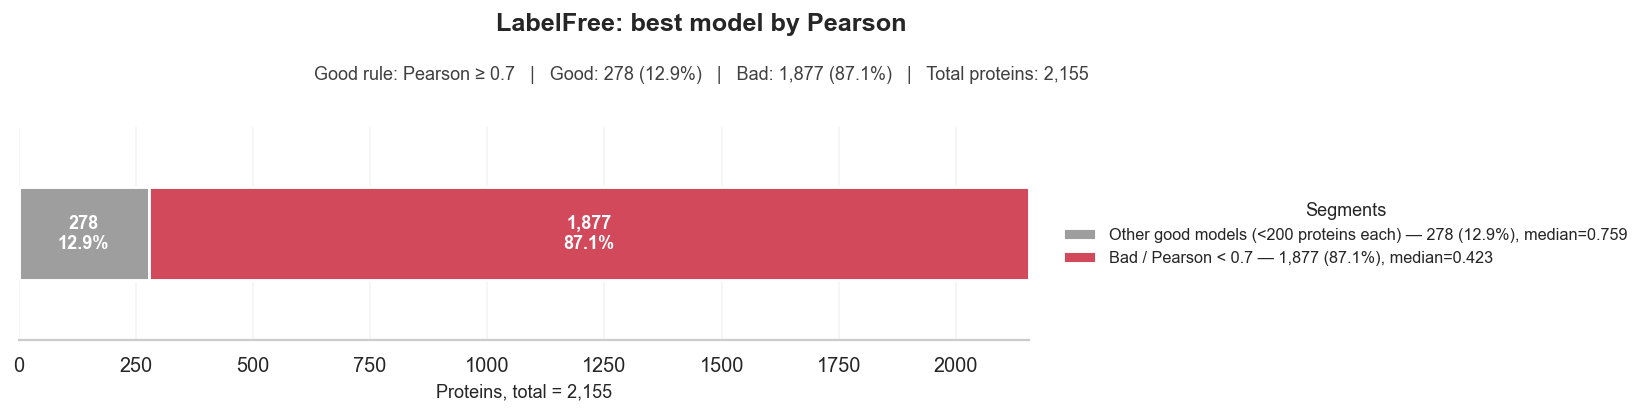


cosine similarity family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 2,155
Good proteins: 107 (5.0%)
Bad proteins:  2,048 (95.0%)
Good proteins best predicted by XGB:                16
Good proteins best predicted by ENet:               91
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,share_percent,median_metric
0,Other good models (<200 proteins each),107,5.0,0.758215
1,Bad / cosine similarity < 0.7,2048,95.0,0.283279



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,share_percent,median_metric
0,results_enet | zscore | fast | k2000,38,1.8,0.759100
1,res_enet_zbig | zscore | fast | k5000,34,1.6,0.738425
2,results_enet | ranking | fast | k2000,10,0.5,0.769150
3,results_enet | unknown | fast | k2000,5,0.2,0.816260
4,results_xgb | rank | fast | k2000,5,0.2,0.760141
5,results_enet | none | fast | k2000,4,0.2,0.753228
6,results_xgb | qbin50 | fast | k2000,4,0.2,0.735115
7,res_xgb_zbig | zscore | current | k5000,3,0.1,0.775065
8,results_xgb | zscore | fast | k2000,3,0.1,0.797895
9,results_xgb | none | fast | k2000,1,0.0,0.730450


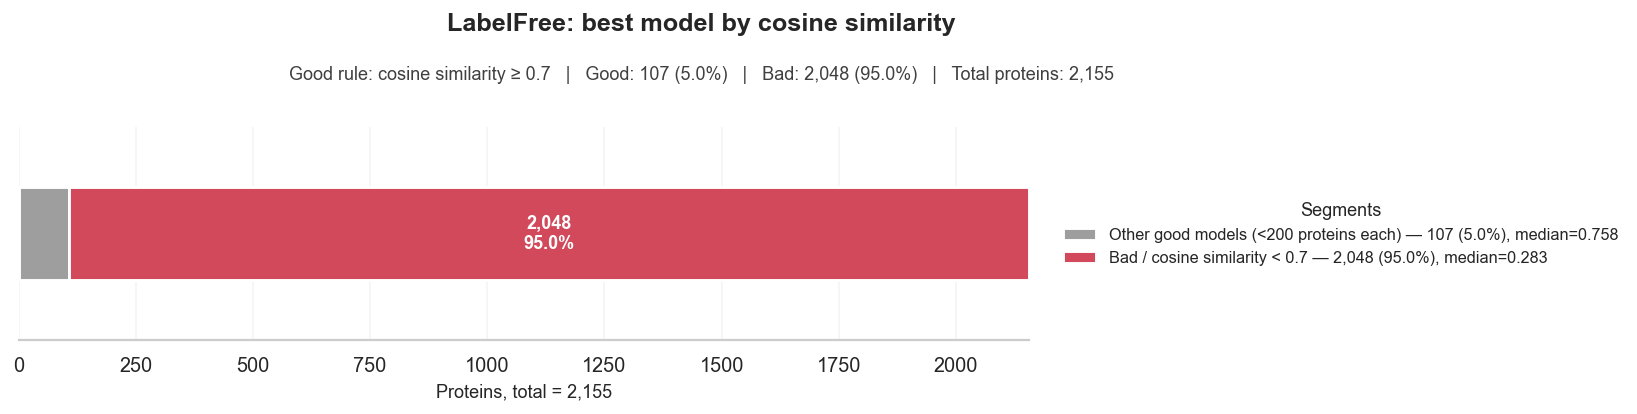


MSE family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 2,155
Good proteins: 539 (25.0%)
Bad proteins:  1,616 (75.0%)
Good proteins best predicted by XGB:                245
Good proteins best predicted by ENet:               294
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,share_percent,median_metric
0,Other good models (<200 proteins each),539,25.0,0.367548
1,Bad / MSE > 0.497,1616,75.0,0.965585



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,share_percent,median_metric
0,results_xgb | none | fast | k2000,165,7.7,0.364378
1,res_enet_zbig | zscore | fast | k5000,120,5.6,0.357232
2,results_enet | zscore | fast | k2000,111,5.2,0.378127
3,results_enet | unknown | fast | k2000,35,1.6,0.326974
4,results_enet | none | fast | k2000,28,1.3,0.347587
5,results_xgb | zscore | fast | k2000,28,1.3,0.395271
6,results_xgb | qbin50 | fast | k2000,22,1.0,0.361534
7,res_xgb_zbig | zscore | current | k5000,19,0.9,0.383497
8,results_xgb | rank | fast | k2000,11,0.5,0.428400


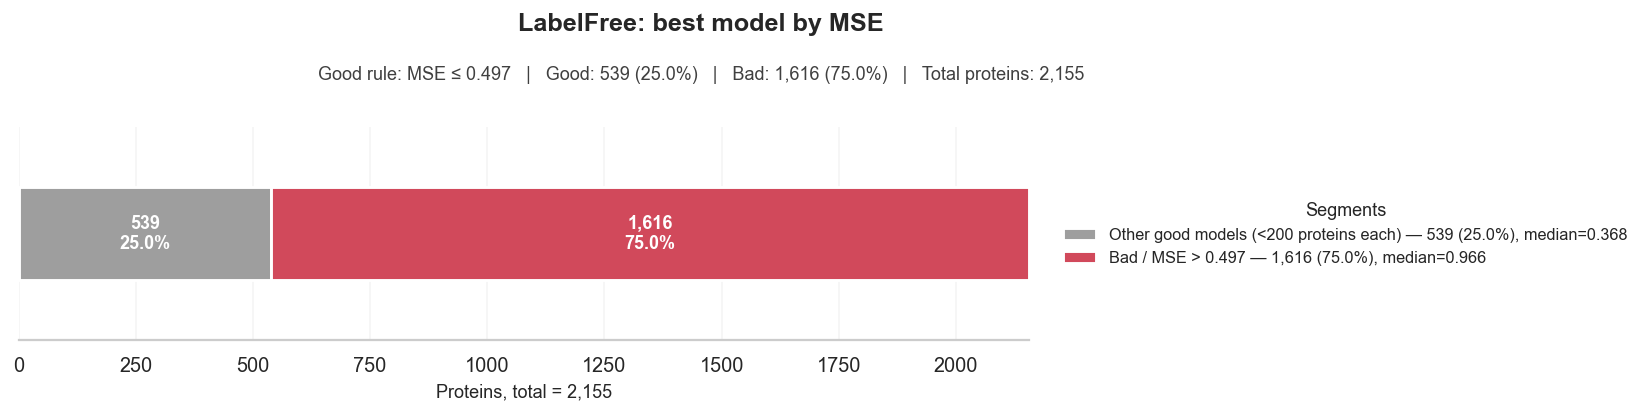


DATASET: TMT

Pearson family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 2,155
Good proteins: 2 (0.1%)
Bad proteins:  2,153 (99.9%)
Good proteins best predicted by XGB:                0
Good proteins best predicted by ENet:               2
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,share_percent,median_metric
0,Other good models (<200 proteins each),2,0.1,0.717095
1,Bad / Pearson < 0.7,2153,99.9,0.390793



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,share_percent,median_metric
0,res_enet_zbig | zscore | fast | k5000,1,0.0,0.720409
1,results_enet | ranking | fast | k2000,1,0.0,0.713781


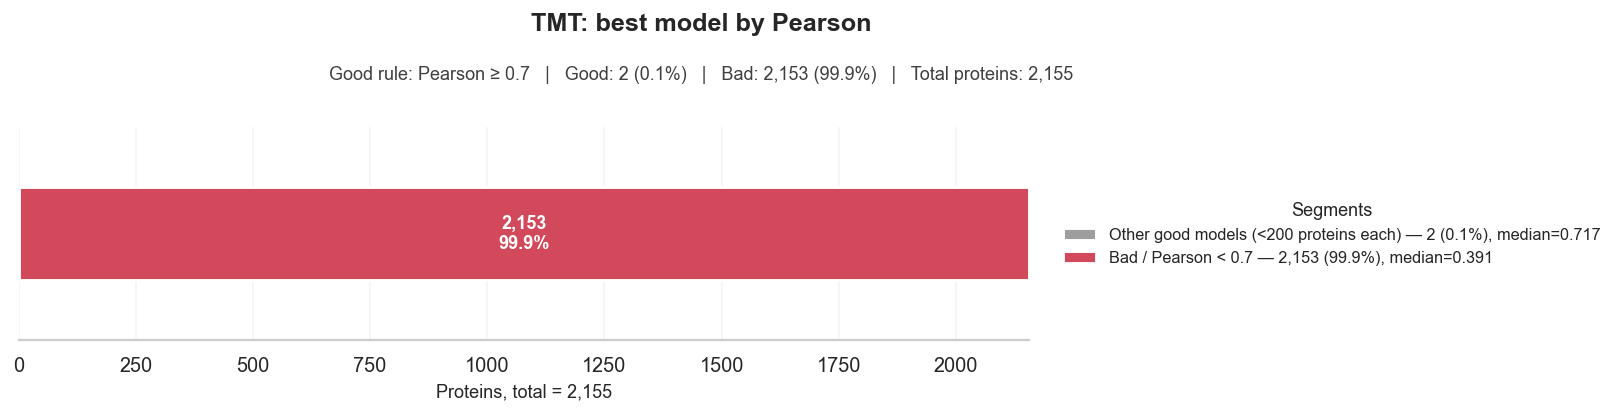


cosine similarity family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 2,155
Good proteins: 0 (0.0%)
Bad proteins:  2,155 (100.0%)
Good proteins best predicted by XGB:                0
Good proteins best predicted by ENet:               0
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,share_percent,median_metric
0,Bad / cosine similarity < 0.7,2155,100.0,0.318666


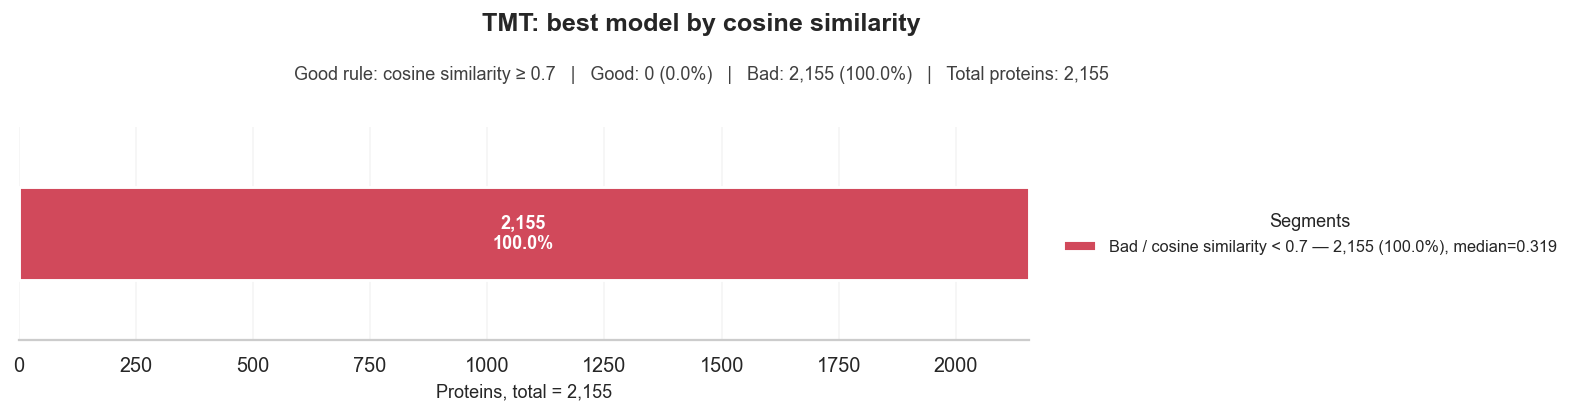


MSE family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 2,155
Good proteins: 539 (25.0%)
Bad proteins:  1,616 (75.0%)
Good proteins best predicted by XGB:                219
Good proteins best predicted by ENet:               320
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,share_percent,median_metric
0,Other good models (<200 proteins each),539,25.0,4.767630
1,Bad / MSE > 6.53,1616,75.0,11.663858



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,share_percent,median_metric
0,res_enet_zbig | zscore | fast | k5000,165,7.7,4.750213
1,results_enet | zscore | fast | k2000,137,6.4,5.061239
2,results_xgb | rank | fast | k2000,61,2.8,4.689134
3,results_xgb | qbin50 | fast | k2000,53,2.5,4.595890
4,res_xgb_zbig | zscore | current | k5000,49,2.3,4.138150
5,results_xgb | zscore | fast | k2000,34,1.6,3.924353
6,results_xgb | none | fast | k2000,22,1.0,4.906524
7,results_enet | unknown | fast | k2000,11,0.5,6.348032
8,results_enet | none | fast | k2000,7,0.3,5.109171


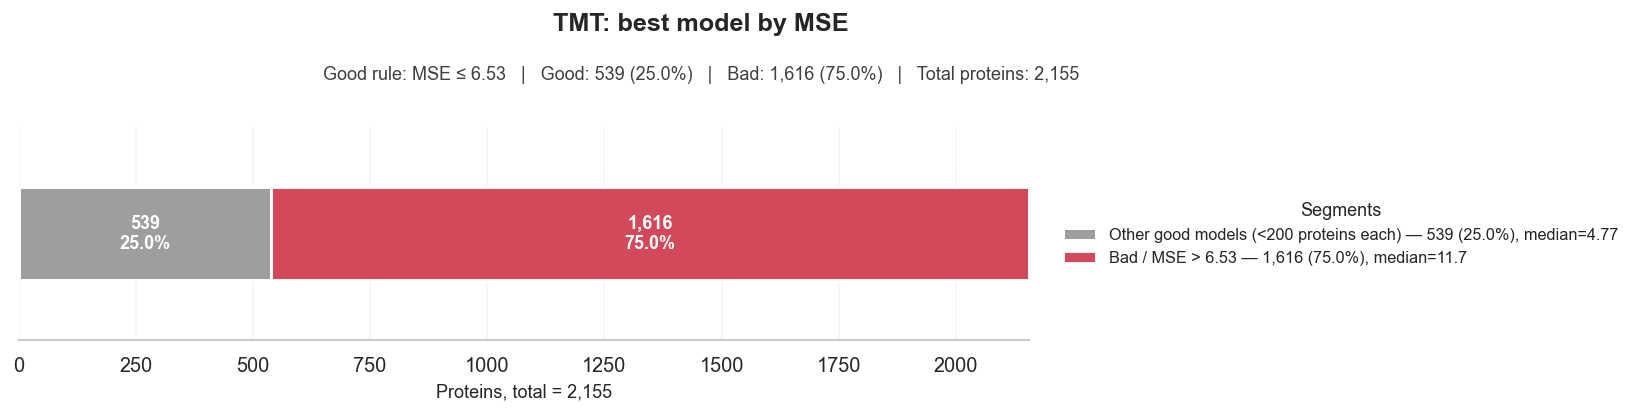


DATASET: iTRAQ

Pearson family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 2,155
Good proteins: 2 (0.1%)
Bad proteins:  2,153 (99.9%)
Good proteins best predicted by XGB:                1
Good proteins best predicted by ENet:               1
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,share_percent,median_metric
0,Other good models (<200 proteins each),2,0.1,0.705658
1,Bad / Pearson < 0.7,2153,99.9,0.192243



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,share_percent,median_metric
0,res_xgb_zbig | zscore | current | k5000,1,0.0,0.708957
1,results_enet | ranking | fast | k2000,1,0.0,0.702360


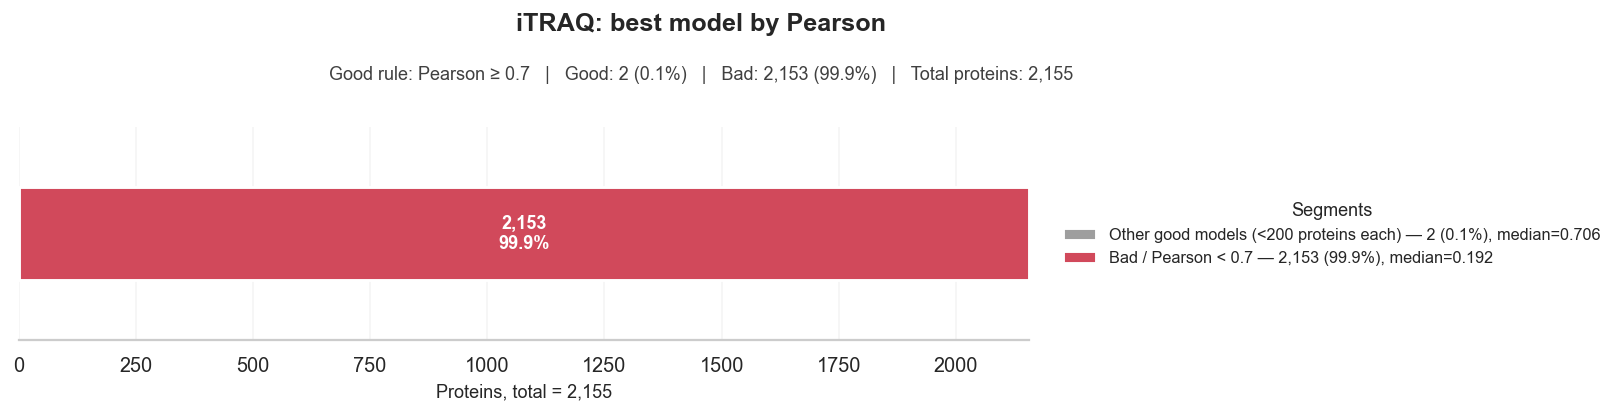


cosine similarity family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 2,155
Good proteins: 0 (0.0%)
Bad proteins:  2,155 (100.0%)
Good proteins best predicted by XGB:                0
Good proteins best predicted by ENet:               0
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,share_percent,median_metric
0,Bad / cosine similarity < 0.7,2155,100.0,0.067596


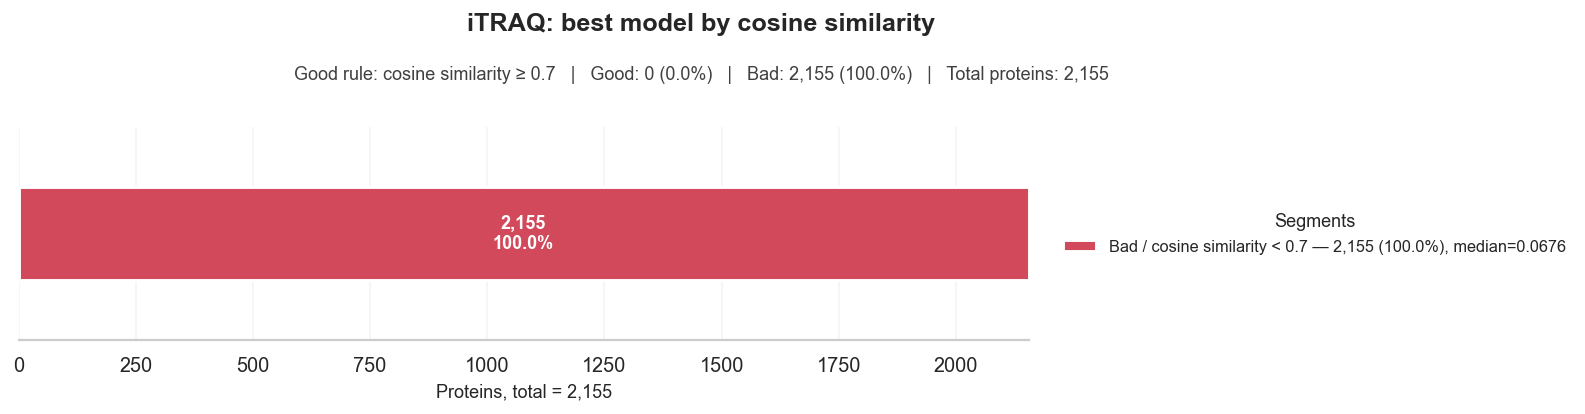


MSE family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 2,155
Good proteins: 539 (25.0%)
Bad proteins:  1,616 (75.0%)
Good proteins best predicted by XGB:                156
Good proteins best predicted by ENet:               383
Good proteins best predicted by same-gene baseline: 0

Visible bar segments:


,partition_label,proteins,share_percent,median_metric
0,Other good models (<200 proteins each),539,25.0,0.188293
1,Bad / MSE > 0.226,1616,75.0,0.360109



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,share_percent,median_metric
0,results_enet | zscore | fast | k2000,177,8.2,0.184428
1,res_enet_zbig | zscore | fast | k5000,141,6.5,0.193079
2,results_xgb | qbin50 | fast | k2000,41,1.9,0.186332
3,results_enet | none | fast | k2000,40,1.9,0.189536
4,results_xgb | rank | fast | k2000,38,1.8,0.194238
5,res_xgb_zbig | zscore | current | k5000,28,1.3,0.174818
6,results_xgb | none | fast | k2000,28,1.3,0.193824
7,results_enet | unknown | fast | k2000,25,1.2,0.190340
8,results_xgb | zscore | fast | k2000,21,1.0,0.164316


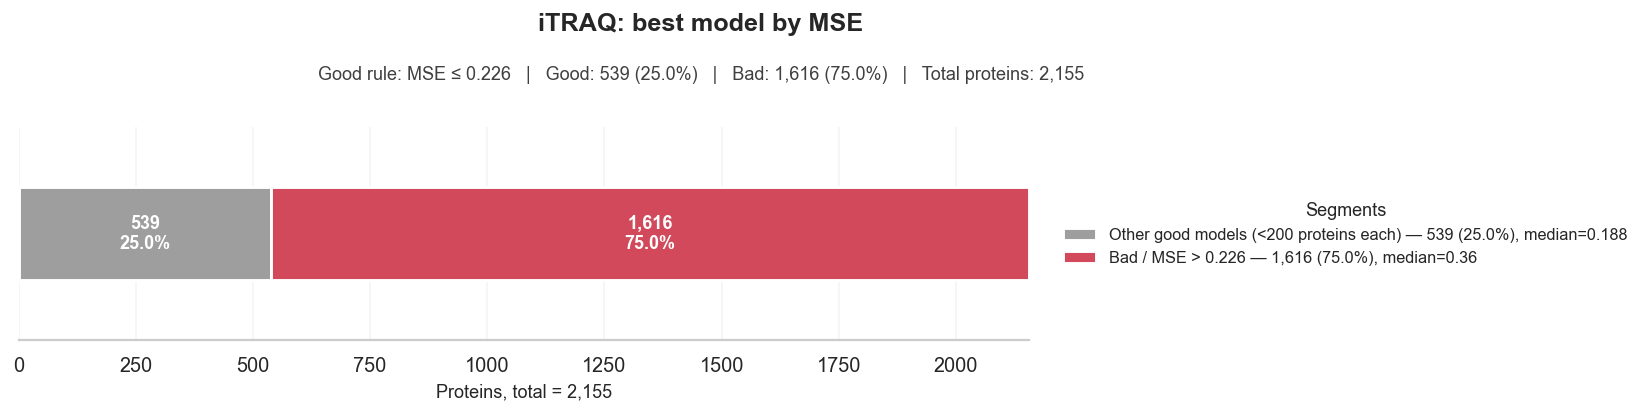

In [10]:
# Exclude exact k50 and k500 runs from this analysis.
# This keeps k5000.
skip_k_pattern = r"(?<![A-Za-z0-9])k(?:50|500)(?![A-Za-z0-9])"

skip_mask = (
    metrics_by_protein["run_label"]
    .astype(str)
    .str.contains(skip_k_pattern, case=False, regex=True, na=False)
)

metrics_partition = metrics_by_protein.loc[~skip_mask].copy()

print(
    f"Using {len(metrics_partition):,} rows after excluding "
    f"{skip_mask.sum():,} k50/k500 rows."
)

partition_tables = {}

for dataset_name in sorted(metrics_partition["dataset"].dropna().unique()):
    print("\n" + "=" * 110)
    print(f"DATASET: {dataset_name}")
    print("=" * 110)

    ds = metrics_partition[metrics_partition["dataset"] == dataset_name].copy()

    best_pearson = best_by_metric(ds, "test_pearson_corr", higher=True)
    best_cosine = best_by_metric(ds, "test_cosine_similarity", higher=True)
    best_mse = best_by_metric(ds, "test_mse", higher=False)

    mse_values = best_mse["test_mse"].dropna()

    mse_threshold = (
        float(mse_values.quantile(MSE_GOOD_PERCENTILE / 100.0))
        if len(mse_values)
        else np.nan
    )

    partition_tables[(dataset_name, "pearson")] = plot_partition_bar(
        best_pearson,
        metric="test_pearson_corr",
        threshold=PEARSON_GOOD_THRESHOLD,
        higher=True,
        title=f"{dataset_name}: best model by Pearson",
        min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
    )

    partition_tables[(dataset_name, "cosine")] = plot_partition_bar(
        best_cosine,
        metric="test_cosine_similarity",
        threshold=COSINE_GOOD_THRESHOLD,
        higher=True,
        title=f"{dataset_name}: best model by cosine similarity",
        min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
    )

    partition_tables[(dataset_name, "mse")] = plot_partition_bar(
        best_mse,
        metric="test_mse",
        threshold=mse_threshold,
        higher=False,
        title=f"{dataset_name}: best model by MSE",
        min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
    )

## 4. Tissue-level summary of winning model families

In [6]:
if metrics_by_tissue.empty:
    print("No tissue-level metrics were found. Run notebook 7 first.")
else:
    print("Tissue-level metric rows:", len(metrics_by_tissue))
    for dataset_name in sorted(metrics_by_tissue["dataset"].dropna().unique()):
        sub = metrics_by_tissue[metrics_by_tissue["dataset"] == dataset_name].copy()
        if sub.empty:
            continue
        best_tissue_pearson = (
            sub.dropna(subset=["test_pearson_corr"])
            .sort_values(["tissue", "test_pearson_corr"], ascending=[True, False])
            .groupby("tissue", as_index=False)
            .head(1)
        )
        print("\n", dataset_name, "best tissue-level Pearson winners")
        display(best_tissue_pearson[["tissue", "run_label", "test_pearson_corr", "n_samples", "n_proteins"]].sort_values("test_pearson_corr", ascending=False).head(20))

        fig, ax = plt.subplots(figsize=(12, max(4, 0.35 * best_tissue_pearson["tissue"].nunique())))
        plot_data = best_tissue_pearson.sort_values("test_pearson_corr", ascending=True).tail(25)
        sns.barplot(data=plot_data, y="tissue", x="test_pearson_corr", hue="run_label", dodge=False, ax=ax)
        ax.set_title(f"{dataset_name}: best run per tissue by Pearson")
        ax.set_xlabel("Tissue-level Pearson across all protein/sample pairs")
        ax.set_ylabel("Tissue")
        ax.legend(loc="lower right", fontsize=8, frameon=True)
        plt.tight_layout()
        plt.show()


No tissue-level metrics were found. Run notebook 7 first.


## 5. Optional exports

In [7]:
# Optional: save partition tables.
# Uncomment if needed.
# out_dir = OUTPUT_DIR / "partition_tables"
# out_dir.mkdir(parents=True, exist_ok=True)
# for (dataset_name, metric_name), table in partition_tables.items():
#     table.to_csv(out_dir / f"partition_{dataset_name}_{metric_name}.csv", index=False)
# print("Saved partition tables to", out_dir)
